# Stage 8: Machine learning models
We compare four model families, from most to least interpretable:

| Model | Why it's here |
|---|---|
| **Logistic Regression** | Industry baseline: transparent coefficients, the basis of traditional scorecards, easy to approve |
| **Random Forest** (optional) | Non-linear bagging benchmark |
| **XGBoost** | Gradient boosting, strong on tabular data, handles missing values natively |
| **LightGBM** | Gradient boosting, faster on large data, typically the strongest on Home Credit |

Each model is trained on the train split, uses the validation split for early stopping (boosting) and for
**Platt calibration**, and is compared on the validation split. The test split stays untouched until Stage 9.

In [1]:
import sys
import time
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from credit_risk.artifacts import load_feature_contract, load_features, load_split_frames, read_json, write_json
from credit_risk.config import get_paths, load_config
from credit_risk.evaluation import compare_models, plot_roc_curves
from credit_risk.modeling import MODEL_LABELS, CreditRiskModel, best_iteration, train_model, tune_lightgbm
from credit_risk.viz import savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()
ID, TARGET = cfg["data"]["id_column"], cfg["data"]["target"]
SEED = cfg["project"]["random_state"]

train, valid, test = load_split_frames(paths)
num_cols, cat_cols = load_feature_contract(paths)
pos_weight = read_json(paths["models"] / "preprocessing_info.json")["pos_weight"]
y_train, y_valid = train[TARGET], valid[TARGET]
print(f"train {train.shape} | valid {valid.shape} | {len(num_cols) + len(cat_cols)} features | pos_weight {pos_weight:.1f}")

train (215257, 244) | valid (46127, 244) | 200 features | pos_weight 11.4


## 1. Train and calibrate every candidate

In [2]:
candidates = [m for m in cfg["modeling"]["candidates"] if m != "random_forest" or cfg["modeling"]["run_random_forest"]]
models, timings = {}, {}
for name in candidates:
    start = time.time()
    pipe = train_model(name, train, y_train, valid, y_valid, num_cols, cat_cols, pos_weight, SEED)
    model = CreditRiskModel(name, pipe, num_cols, cat_cols, metadata={"best_iteration": best_iteration(pipe)})
    model.calibrate(valid, y_valid)
    models[name] = model
    timings[name] = time.time() - start
    it = model.metadata["best_iteration"]
    print(f"{MODEL_LABELS[name]:<20} trained in {timings[name]:6.1f}s" + (f" | best iteration {it}" if it else ""))

Logistic Regression  trained in   20.0s
Random Forest        trained in   68.3s
XGBoost              trained in  151.2s | best iteration 964
LightGBM             trained in   60.4s | best iteration 984


## 2. Optional: hyper-parameter search for LightGBM
Off by default (`modeling.tuning.enabled` in config). A small random search with early stopping on the validation set
is usually enough on this data. Gains beyond that are small compared with better features.

In [3]:
if cfg["modeling"]["tuning"]["enabled"]:
    best_params, tuned_pipe, search = tune_lightgbm(train, y_train, valid, y_valid, num_cols, cat_cols, pos_weight,
                                                    n_iter=cfg["modeling"]["tuning"]["n_iter"], random_state=SEED)
    display(search.head(10))
    tuned = CreditRiskModel("lightgbm", tuned_pipe, num_cols, cat_cols, metadata={"best_iteration": best_iteration(tuned_pipe), "params": best_params})
    models["lightgbm_tuned"] = tuned.calibrate(valid, y_valid)
    search.to_csv(paths["reports"] / "lightgbm_tuning.csv", index=False)
else:
    print("Tuning disabled; using default hyper-parameters.")

Tuning disabled; using default hyper-parameters.


## 3. Compare on the validation set
Threshold-free metrics first: **ROC-AUC / Gini** (ranking), **KS** (max separation), **PR-AUC** (performance on the
minority class) and **Brier score** (calibration + sharpness, lower is better).

*Caveat:* the validation set was also used for early stopping and calibration, so these numbers are slightly
optimistic. The unbiased comparison is in Stage 9 on the test set.

In [4]:
valid_preds = {MODEL_LABELS.get(n, n): (y_valid.to_numpy(), m.predict_pd(valid)) for n, m in models.items()}
comparison = compare_models(valid_preds)[["roc_auc", "gini", "ks", "pr_auc", "brier", "log_loss"]]
comparison["train_seconds"] = [timings.get(next((k for k, v in MODEL_LABELS.items() if v == i), i), np.nan) for i in comparison.index]
comparison.round(4)

,roc_auc,gini,ks,pr_auc,brier,log_loss,train_seconds
model,,,,,,,
LightGBM,0.7900,0.5801,0.4345,0.2875,0.0657,0.2358,60.3959
XGBoost,0.7891,0.5781,0.4341,0.2846,0.0657,0.2362,151.1917
Logistic Regression,0.7770,0.5540,0.4163,0.2638,0.0668,0.2407,19.9939
Random Forest,0.7660,0.5319,0.3999,0.2531,0.0674,0.2438,68.3126


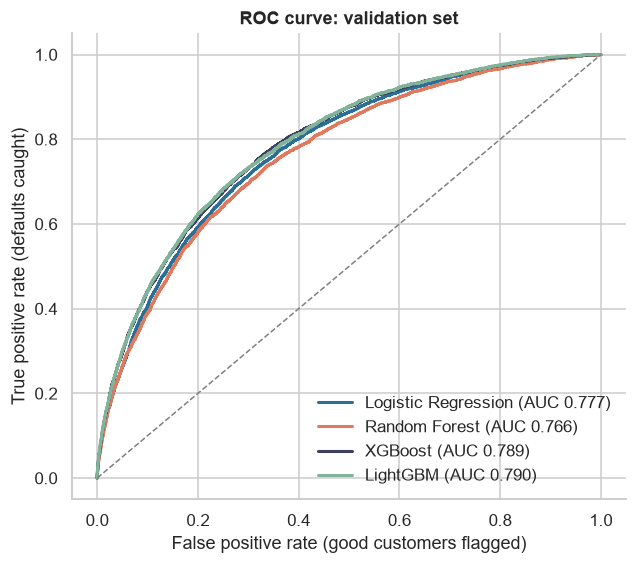

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_roc_curves(valid_preds, ax=ax)
ax.set_title("ROC curve: validation set")
savefig(fig, "model_roc_validation")
plt.show()

## 4. Overfitting check: train vs validation AUC

In [6]:
from sklearn.metrics import roc_auc_score

sample_train = train.sample(min(len(train), 50_000), random_state=SEED)
gap = pd.DataFrame({
    "train_auc": {MODEL_LABELS.get(n, n): roc_auc_score(sample_train[TARGET], m.predict_pd(sample_train)) for n, m in models.items()},
    "valid_auc": {MODEL_LABELS.get(n, n): roc_auc_score(y_valid, m.predict_pd(valid)) for n, m in models.items()},
})
gap["gap"] = gap["train_auc"] - gap["valid_auc"]
gap.round(4)

,train_auc,valid_auc,gap
Logistic Regression,0.7770,0.7770,0.0000
Random Forest,0.8606,0.7660,0.0946
XGBoost,0.8735,0.7891,0.0844
LightGBM,0.8690,0.7900,0.0790


A large train-validation gap means memorisation. Early stopping, `min_child_samples` and column subsampling keep it in check for the boosters.

## 5. Select the champion and save everything
**Selection rule:** highest validation ROC-AUC. In practice a bank would weigh this against explainability and
operational cost. If logistic regression is within ~0.01 AUC of the best model, many teams would deploy it as the
champion and run the booster as a *challenger*.

In [7]:
best_label = comparison["roc_auc"].idxmax()
best_name = next(k for k in models if MODEL_LABELS.get(k, k) == best_label)
champion = models[best_name]
champion.metadata.update({"selected_by": "validation roc_auc", "valid_auc": float(comparison.loc[best_label, "roc_auc"]),
                          "trained_on_rows": len(train), "pos_weight": pos_weight})
print(f"Champion: {best_label} (valid AUC {comparison.loc[best_label, 'roc_auc']:.4f})")

for name, m in models.items():
    m.save(paths["models"] / f"{name}.joblib")
champion.save(paths["models"] / "final_model.joblib")
comparison.to_csv(paths["reports"] / "model_comparison_validation.csv")
write_json({"champion": best_name, "champion_label": best_label, "candidates": list(models)}, paths["models"] / "model_registry.json")

Champion: LightGBM (valid AUC 0.7900)


## 6. Score the Kaggle test set (optional)
`application_test` has no labels. Scoring it gives a file you can submit to Kaggle to get an independent AUC
from the public/private leaderboard, which is a nice extra validation point for your portfolio.

In [8]:
kaggle_test = load_features(paths, "test")
submission = pd.DataFrame({ID: kaggle_test[ID], TARGET: champion.predict_pd(kaggle_test)})
submission.to_csv(paths["reports"] / "kaggle_submission.csv", index=False)
submission.describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,48744.0,277796.676350,103169.547296,100001.000000,188557.750000,277549.000000,367555.500000,456250.000000
TARGET,48744.0,0.073153,0.083101,0.000654,0.017182,0.040809,0.097677,0.662822
